In [12]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

from qss.solver_options import brent_defaults, sa_defaults
from qss.chemical_potential import chemical_potential
from qss.distributions import DistType, prepare_2D_lattice_data

In [13]:
MU_B  = 5.788381806e-5# eV/T
N = 100
t = -1
t_prim = 0.25
# t_prim = 0

kx = np.linspace(-np.pi, np.pi, N, endpoint=False)
ky = np.linspace(-np.pi, np.pi, N, endpoint=False)
e_k, _, _ = prepare_2D_lattice_data(kx, ky, t, t_prim)

In [14]:
# Band filling values
n_min = 0.1
n_max = 0.99
n_count = 20

# Magnetic field values
Ha_min = -2
Ha_max = 4
Ha_count = 5

# Beta values

beta_min = -2
beta_max = 1
beta_count = 2

distros = [DistType.FD, DistType.FLB, DistType.NFLB]  # ND
# n  = np.array([0.5, 0.8, 0.9], dtype=np.float64)  # NN
n  = np.linspace(n_min, n_max, n_count, dtype=np.float64)  # NN
# beta = np.array([0.1, 1.0], dtype=np.float64)  # NB
beta = np.logspace(beta_min, beta_max, beta_count, dtype=np.float64)  # NB
# H_a = np.array([0.0], dtype=np.float64) # NH
H_a = np.logspace(Ha_min, Ha_max, Ha_count, dtype=np.float64) # NH
H_a = np.concat([np.array([0.0]), H_a])

In [15]:
py_opts = brent_defaults(
    abs_tol=1e-9, 
    rel_tol=1e-6, 
    expand_factor=1.4,
    initial_step=10.0,  
    max_expands=64,
    max_iters=5000      
)
native_opts= py_opts.to_qss()

In [16]:
# py_opts = sa_defaults(T0=5e3,
#                       T_min=1e-8,
#                       alpha=0.95,
#                       max_iters=1e6,
#                       min_iters = 85,
#                       stall_iters=65,
#                       step_decay=0.95,
#                       step_sigma=2.15,
#                       bounds=[(-3., 3.)]
#                       )
# native_opts= py_opts.to_qss()

In [17]:
mu_df = chemical_potential(
    distros=["FD", "FLB", "NFLB"],
    n_vals=n,
    beta_vals=beta,
    H_a_vals=H_a,
    N=N,
    E=e_k,
    solver_opts=native_opts,
    x0=10.,
    a0=-5.0,
    b0=5.0,
)
mu_df.to_csv("chemical_potential_results.csv")
mu_df

mu  iterations  converged      residual
distro n        k_BT  H_a                                                     
FD     0.100000 100.0 0.0     -294.454038          23       True  1.448324e-08
       0.146842 100.0 0.0     -253.538484          21       True  4.373061e-08
       0.193684 100.0 0.0     -223.290569          23       True  9.474731e-08
       0.240526 100.0 0.0     -199.002595          23       True  3.452742e-09
       0.287368 100.0 0.0     -178.510209          20       True  1.499144e-07
...                                   ...         ...        ...           ...
NFLB   0.802632 0.1   10000.0   -0.516893          26       True  2.709557e-08
       0.849474 0.1   10000.0   -0.414089          26       True  6.143487e-08
       0.896316 0.1   10000.0   -0.308355          26       True  1.075817e-08
       0.943158 0.1   10000.0   -0.200230          27       True  1.434111e-08
       0.990000 0.1   10000.0   -0.090785          28       True  5.739491e-09

[720 rows x 4 columns]

<Axes: xlabel='n', ylabel='mu'>

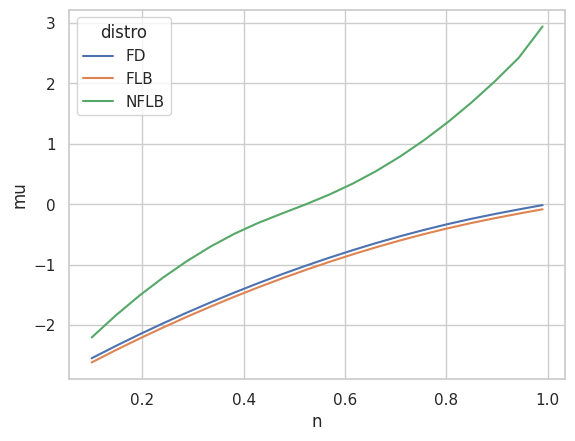

In [22]:
data = mu_df.loc[(["FD","FLB","NFLB"], n, 1/beta[-1], H_a[0]), :]
fig,ax = plt.subplots()
sns.lineplot(data= data, x="n", y="mu", hue="distro", markers=True, ax=ax)
# ax.set_ylim(-3,3)

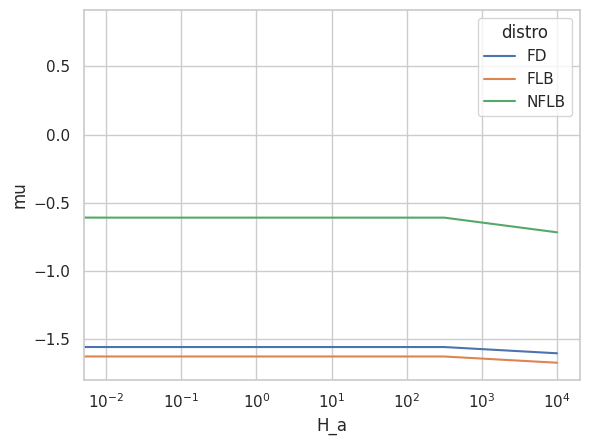

In [19]:
data = mu_df.loc[(["FD","FLB", "NFLB"], n[-7], 1/beta[-1], H_a), :]
fig,ax = plt.subplots()
# data = data.abs()
sns.lineplot(data= data, x="H_a", y="mu", hue="distro", markers=True, ax=ax)
# ax.set_ylim(-0.1,0.1)
ax.set_xscale("log")


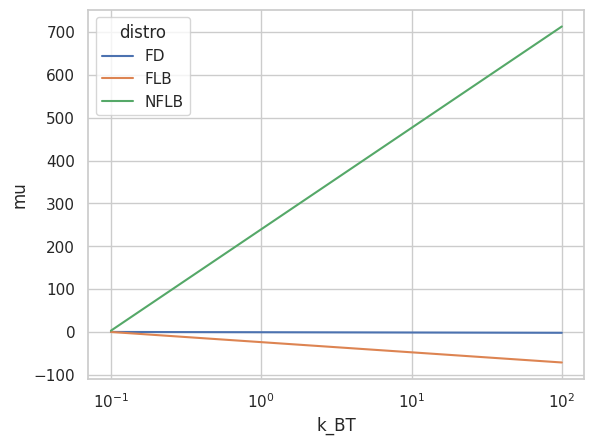

In [20]:
data = mu_df.loc[(["FD","FLB", "NFLB"], n[-1], 1/beta, H_a[0]), :]  # Series with MultiIndex (dist, n)

fig,ax = plt.subplots()
sns.lineplot(data= data, x="k_BT", y="mu", hue="distro", markers=True, ax=ax)
ax.set_xscale("log")